**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 2**
Pandas para el análisis de datos en Python

---

*   NOMBRE: Jacinto Manuel Molina Peralta
*   MATRÍCULA: A01841486


---

En esta actividad trabajarás con el archivo `cleaned_weather.csv`, un extracto del conjunto de datos meteorológicos a lo largo de todo el año 2020 en una estación del Instituto *Max Planck* (Alemania) disponible en Kaggle.

Los datos meteorológicos fueron registrados cada 10 minutos e incluyen los siguientes indicadores:

*   `timestamp`: Fecha y hora de la observación.
*   `p`: Presión atmosférica en milibares (mbar)
*   `T`: Temperatura del aire en grados Celsius (°C)
*   `Tpot`: Temperatura potencial en Kelvin (K)
*   `rh`: Humedad relativa en porcentaje (%)
*   `VPact`: Presión real de vapor en milibares (mbar)
*   `sh`: Humedad específica en gramos por kilogramo (g/kg)
*   `H2OC`: Concentración de vapor de agua en milimoles por mol (mmol/mol) de aire seco
*   `rho`: Densidad del aire en gramos por metro cúbico (g/m³)
*   `wv`: Velocidad del viento en metros por segundo (m/s)
*   `wd`: Dirección del viento en grados (°)
*   `rain`: Precipitación total en milímetros (mm)
*   `raining`: Duración de la lluvia en segundos (s)

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.


In [1]:
# Importa las librerías necesarias
import pandas as pd
import matplotlib.pyplot as plt

1.	Descarga el archivo: `cleaned_weather.csv` y guarda, en un dataframe (`weather_df`), todos sus registros.
- Determina la dimensionalidad del dataframe y obtén los identificadores de columnas.
- Renombra las columnas para facilitar la interpretación de los indicadores en los ejercicios siguientes:
  - `medicion, presion_atmosferica, temperatura_celsius, temperatura_kelvin, humedad_relativa, presion_vapor, humedad_especifica, concentracion_vapor, densidad_aire, velocidad_viento, direccion_viento, precipitacion_total, duracion_lluvia`
- Muestra los primeros y los últimos 5 registros.
- ¿Hay valores faltantes en el dataframe?





In [2]:
weather_df = pd.read_csv('cleaned_weather.csv')
weather_df.shape

(52696, 13)

In [3]:
weather_df.columns

Index(['timestamp', 'p', 'T', 'Tpot', 'rh', 'VPact', 'sh', 'H2OC', 'rho', 'wv',
       'wd', 'rain', 'raining'],
      dtype='object')

In [4]:
weather_df.columns = ['medicion', 'presion_atmosferica', 'temperatura_celsius',
                      'temperatura_kelvin', 'humedad_relativa', 'presion_vapor',
                      'humedad_especifica', 'concentracion_vapor', 'densidad_aire',
                      'velocidad_viento', 'direccion_viento', 'precipitacion_total',
                      'duracion_lluvia']
weather_df.columns

Index(['medicion', 'presion_atmosferica', 'temperatura_celsius',
       'temperatura_kelvin', 'humedad_relativa', 'presion_vapor',
       'humedad_especifica', 'concentracion_vapor', 'densidad_aire',
       'velocidad_viento', 'direccion_viento', 'precipitacion_total',
       'duracion_lluvia'],
      dtype='object')

In [5]:
weather_df.head()

,medicion,presion_atmosferica,temperatura_celsius,temperatura_kelvin,humedad_relativa,presion_vapor,humedad_especifica,concentracion_vapor,densidad_aire,velocidad_viento,direccion_viento,precipitacion_total,duracion_lluvia
0,01/01/20 0:10,1008.89,0.71,273.18,86.1,5.54,3.42,5.49,1280.62,1.02,224.3,0.0,0
1,01/01/20 0:20,1008.76,0.75,273.22,85.2,5.49,3.39,5.45,1280.33,0.43,206.8,0.0,0
2,01/01/20 0:30,1008.66,0.73,273.21,85.1,5.48,3.39,5.43,1280.29,0.61,197.1,0.0,0
3,01/01/20 0:40,1008.64,0.37,272.86,86.3,5.41,3.35,5.37,1281.97,1.11,206.4,0.0,0
4,01/01/20 0:50,1008.61,0.33,272.82,87.4,5.47,3.38,5.42,1282.08,0.49,209.6,0.0,0


In [6]:
weather_df.tail()

,medicion,presion_atmosferica,temperatura_celsius,temperatura_kelvin,humedad_relativa,presion_vapor,humedad_especifica,concentracion_vapor,densidad_aire,velocidad_viento,direccion_viento,precipitacion_total,duracion_lluvia
52691,31/12/20 23:20,978.32,2.28,277.16,80.0,5.76,3.67,5.89,1234.61,0.73,180.6,0.0,0
52692,31/12/20 23:30,978.30,2.13,277.01,83.1,5.92,3.77,6.05,1235.20,0.43,174.0,0.0,0
52693,31/12/20 23:40,978.26,1.99,276.88,82.2,5.80,3.69,5.93,1235.82,0.38,248.9,0.0,0
52694,31/12/20 23:50,978.26,2.07,276.95,81.4,5.77,3.68,5.90,1235.49,0.57,196.6,0.0,0
52695,01/01/21 0:00,978.24,2.01,276.89,82.4,5.82,3.71,5.95,1235.71,0.57,221.3,0.0,0


In [7]:
weather_df.isna().sum()

,0
medicion,0
presion_atmosferica,0
temperatura_celsius,0
temperatura_kelvin,0
humedad_relativa,0
presion_vapor,0
humedad_especifica,0
concentracion_vapor,0
densidad_aire,0
velocidad_viento,0


No hay valores faltantes, todas las columnas tienen 0 valores nulos.

2. Determina el tipo de datos que tienen las columnas.
- Cambia la columna `medicion` a datetime utilizando el formato: `%d/%m/%y %H:%M`
- Obtén dos columnas adicionales separando `medicion` en `fecha` y `hora`

In [8]:
weather_df.dtypes

,0
medicion,object
presion_atmosferica,float64
temperatura_celsius,float64
temperatura_kelvin,float64
humedad_relativa,float64
presion_vapor,float64
humedad_especifica,float64
concentracion_vapor,float64
densidad_aire,float64
velocidad_viento,float64


La columna medicion es de tipo object, o sea que se leyó como texto. duracion_lluvia es int64 porque son segundos enteros y las demás columnas son float64.

In [9]:
weather_df['medicion'] = pd.to_datetime(weather_df['medicion'], format='%d/%m/%y %H:%M')
weather_df['fecha'] = weather_df['medicion'].dt.date
weather_df['hora'] = weather_df['medicion'].dt.time
weather_df.head()

,medicion,presion_atmosferica,temperatura_celsius,temperatura_kelvin,humedad_relativa,presion_vapor,humedad_especifica,concentracion_vapor,densidad_aire,velocidad_viento,direccion_viento,precipitacion_total,duracion_lluvia,fecha,hora
0,2020-01-01 00:10:00,1008.89,0.71,273.18,86.1,5.54,3.42,5.49,1280.62,1.02,224.3,0.0,0,2020-01-01,00:10:00
1,2020-01-01 00:20:00,1008.76,0.75,273.22,85.2,5.49,3.39,5.45,1280.33,0.43,206.8,0.0,0,2020-01-01,00:20:00
2,2020-01-01 00:30:00,1008.66,0.73,273.21,85.1,5.48,3.39,5.43,1280.29,0.61,197.1,0.0,0,2020-01-01,00:30:00
3,2020-01-01 00:40:00,1008.64,0.37,272.86,86.3,5.41,3.35,5.37,1281.97,1.11,206.4,0.0,0,2020-01-01,00:40:00
4,2020-01-01 00:50:00,1008.61,0.33,272.82,87.4,5.47,3.38,5.42,1282.08,0.49,209.6,0.0,0,2020-01-01,00:50:00


3. Determina la cantidad de valores únicos de cada columna.
- La columna `medicion` tiene un valor menos que el número total de filas del dataframe, lo que indica que hay una fecha duplicada. Identifica cuál es.
- Comprueba si las demás columnas también contienen los mismos valores; si es así, elimina  uno de los registros duplicados.


In [10]:
weather_df.nunique()

,0
medicion,52695
presion_atmosferica,5052
temperatura_celsius,3680
temperatura_kelvin,3836
humedad_relativa,5494
presion_vapor,2059
humedad_especifica,1337
concentracion_vapor,2087
densidad_aire,14826
velocidad_viento,977


In [11]:
weather_df[weather_df['medicion'].duplicated(keep=False)]

,medicion,presion_atmosferica,temperatura_celsius,temperatura_kelvin,humedad_relativa,presion_vapor,humedad_especifica,concentracion_vapor,densidad_aire,velocidad_viento,direccion_viento,precipitacion_total,duracion_lluvia,fecha,hora
19043,2020-05-12 06:00:00,991.53,-1.57,272.25,96.2,5.24,3.29,5.28,1269.29,1.04,215.4,0.0,0,2020-05-12,06:00:00
19044,2020-05-12 06:00:00,991.53,-1.57,272.25,96.2,5.24,3.29,5.28,1269.29,1.04,215.4,0.0,0,2020-05-12,06:00:00


Con nunique() se ve que medicion tiene 52,695 valores únicos, pero el dataframe tiene 52,696 filas, entonces hay una fecha repetida. La fecha duplicada es 2020-05-12 06:00:00 y está en las filas 19043 y 19044.

In [12]:
weather_df[weather_df.duplicated(keep=False)]

,medicion,presion_atmosferica,temperatura_celsius,temperatura_kelvin,humedad_relativa,presion_vapor,humedad_especifica,concentracion_vapor,densidad_aire,velocidad_viento,direccion_viento,precipitacion_total,duracion_lluvia,fecha,hora
19043,2020-05-12 06:00:00,991.53,-1.57,272.25,96.2,5.24,3.29,5.28,1269.29,1.04,215.4,0.0,0,2020-05-12,06:00:00
19044,2020-05-12 06:00:00,991.53,-1.57,272.25,96.2,5.24,3.29,5.28,1269.29,1.04,215.4,0.0,0,2020-05-12,06:00:00


Al revisar todas las columnas salen las mismas dos filas, entonces no solo se repite la fecha, sino todo el registro. Por eso se eliminó uno con drop_duplicates().

In [13]:
weather_df = weather_df.drop_duplicates()
weather_df.shape

(52695, 15)

4. Imprime nuevamente las cantidad de valores únicos por columna.
- ¿Por qué son 144 horas diferentes?
- La cantidad de combinaciones únicas de fecha y hora no coincide con el número total de mediciones. Aunque no haya valores NaN, esto no garantiza que no se hayan omitido registros. Identifica las fechas en las que faltan mediciones.
- Una vez concluido el análisis de mediciones faltantes, elimina todos los registros que no correspondan al año 2020 y la columna `medicion`.


In [14]:
weather_df.nunique()

,0
medicion,52695
presion_atmosferica,5052
temperatura_celsius,3680
temperatura_kelvin,3836
humedad_relativa,5494
presion_vapor,2059
humedad_especifica,1337
concentracion_vapor,2087
densidad_aire,14826
velocidad_viento,977


Ahora medicion tiene 52,695 valores únicos, igual que el número de filas, así que ya no hay duplicados.

Hay 144 horas diferentes porque se toma una medición cada 10 minutos, o sea 6 por hora, y 24 × 6 = 144 (de 00:00 a 23:50).

In [15]:
registros_por_dia = weather_df.groupby('fecha').size()
registros_por_dia[registros_por_dia < 144]

,0
fecha,
2020-01-01,143
2020-05-29,135
2021-01-01,1


Si un día tiene todas sus mediciones deberían ser 144. Los días que tienen menos son:

- 2020-01-01 con 143: le falta la de las 00:00, porque los datos empiezan a las 00:10.
- 2020-05-29 con 135: le faltan 9 mediciones.

El 2021-01-01 sale con 1 solo registro, pero ese ya es del siguiente año, por eso se elimina junto con la columna medicion.

In [16]:
weather_df = weather_df[weather_df['medicion'].dt.year == 2020].copy()
weather_df = weather_df.drop(columns='medicion')
weather_df.shape

(52694, 14)

5. Obtén un dataframe `indicadores_diarios` que sólo almacene el mayor valor de las mediciones por fecha para responder:
- ¿Cuál fue la máxima precipitación y a qué fecha pertenece?
- ¿Cuáles fueron los tres días con las velocidades de viento más altas registradas?
- ¿Cuántos días rebasaron el 90% de humedad relativa y los 30° celsius?

In [17]:
indicadores_diarios = weather_df.drop(columns='hora').groupby('fecha').max()
indicadores_diarios.head()

,presion_atmosferica,temperatura_celsius,temperatura_kelvin,humedad_relativa,presion_vapor,humedad_especifica,concentracion_vapor,densidad_aire,velocidad_viento,direccion_viento,precipitacion_total,duracion_lluvia
fecha,,,,,,,,,,,,
2020-01-01,1008.89,4.58,277.27,95.0,5.81,3.60,5.77,1298.02,1.91,356.9,0.0,0
2020-01-02,1004.16,6.47,279.72,93.9,5.57,3.48,5.58,1304.37,2.67,358.8,0.0,0
2020-01-03,998.45,8.17,281.80,89.3,9.34,5.86,9.39,1266.97,8.79,336.5,0.2,470
2020-01-04,1003.47,6.61,280.15,91.4,8.54,5.36,8.58,1270.10,4.61,354.7,1.0,600
2020-01-05,1009.07,4.43,277.01,85.3,6.44,3.99,6.40,1275.47,3.14,274.6,0.0,0


In [18]:
indicadores_diarios['precipitacion_total'].max(), indicadores_diarios['precipitacion_total'].idxmax()

(11.2, datetime.date(2020, 6, 16))

La precipitación máxima fue de 11.2 mm, el 16 de junio de 2020.

In [19]:
indicadores_diarios.nlargest(3, 'velocidad_viento')['velocidad_viento']

,velocidad_viento
fecha,
2020-02-10,13.77
2020-02-16,13.00
2020-02-09,12.52


Los tres días con más viento fueron el 10 de febrero (13.77 m/s), el 16 de febrero (13.00 m/s) y el 9 de febrero (12.52 m/s). Los tres son de febrero de 2020.

In [20]:
dias_humedad = (indicadores_diarios['humedad_relativa'] > 90).sum()
dias_temperatura = (indicadores_diarios['temperatura_celsius'] > 30).sum()
dias_ambos = ((indicadores_diarios['humedad_relativa'] > 90) & (indicadores_diarios['temperatura_celsius'] > 30)).sum()
dias_humedad, dias_temperatura, dias_ambos

(np.int64(221), np.int64(9), np.int64(5))

221 días pasaron el 90% de humedad relativa y 9 días pasaron los 30 °C. Si se piden las dos condiciones al mismo tiempo, solo fueron 5 días.

Hay que tomar en cuenta que son los valores máximos de cada día, entonces la humedad y la temperatura más altas no necesariamente pasaron a la misma hora.

6. La función `describe()` resume múltiples estadísticas descriptivas. Utiliza esta función para explorar y responder las preguntas sobre las variables en el dataframe de `indicadores_diarios `:
- ¿Cuál es la desviación estándar de la concentración de vapor y qué indica?
- ¿Cuál es la mediana de la presión atmosférica y qué significa?
- ¿Cuál es el tercer cuartil de la duración de la lluvia y cómo se interpreta?

In [21]:
indicadores_diarios.describe()

,presion_atmosferica,temperatura_celsius,temperatura_kelvin,humedad_relativa,presion_vapor,humedad_especifica,concentracion_vapor,densidad_aire,velocidad_viento,direccion_viento,precipitacion_total,duracion_lluvia
count,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000
mean,992.977842,15.343770,289.431667,90.886530,11.409454,7.214016,11.539180,1232.622814,5.245164,317.673689,0.314208,240.382514
std,8.543447,7.850339,7.942175,9.201588,4.507555,2.872647,4.573267,32.702446,2.097012,50.611324,0.979721,273.840002
min,959.900000,-0.120000,273.460000,55.440000,3.320000,2.050000,3.290000,1167.050000,1.570000,69.570000,0.000000,0.000000
25%,988.015000,8.840000,282.732500,85.400000,7.647500,4.832500,7.742500,1207.590000,3.662500,279.075000,0.000000,0.000000
50%,993.300000,15.060000,289.160000,93.250000,10.715000,6.705000,10.735000,1231.455000,4.880000,346.650000,0.000000,0.000000
75%,998.432500,21.695000,295.957500,99.900000,14.462500,9.180000,14.685000,1256.057500,6.495000,357.300000,0.200000,600.000000
max,1020.070000,34.800000,309.130000,100.000000,24.160000,15.400000,24.530000,1318.520000,13.770000,360.000000,11.200000,600.000000


La desviación estándar de la concentración de vapor es 4.57 mmol/mol y la media es 11.54 mmol/mol. Esto indica qué tanto se alejan los valores de cada día respecto al promedio. Es una variación grande (casi el 40% de la media), lo cual tiene sentido porque en invierno el aire es frío y tiene menos vapor que en verano.

La mediana de la presión atmosférica es 993.30 mbar. Significa que la mitad de los días tuvo una presión máxima menor o igual a ese valor y la otra mitad una mayor. Como la media (992.98 mbar) es casi igual, los datos de presión están bastante balanceados.

El tercer cuartil de la duración de la lluvia es 600 segundos. Quiere decir que el 75% de los días tiene un valor de 600 s o menos. Pero 600 s son 10 minutos, que es todo el intervalo entre mediciones y además es el valor máximo, entonces en al menos una cuarta parte de los días hubo algún intervalo en el que llovió los 10 minutos completos. También la mediana es 0, o sea que en más de la mitad de los días no llovió.

7.	Dibuja un histograma para cada una de las columnas de `indicadores_diarios`.

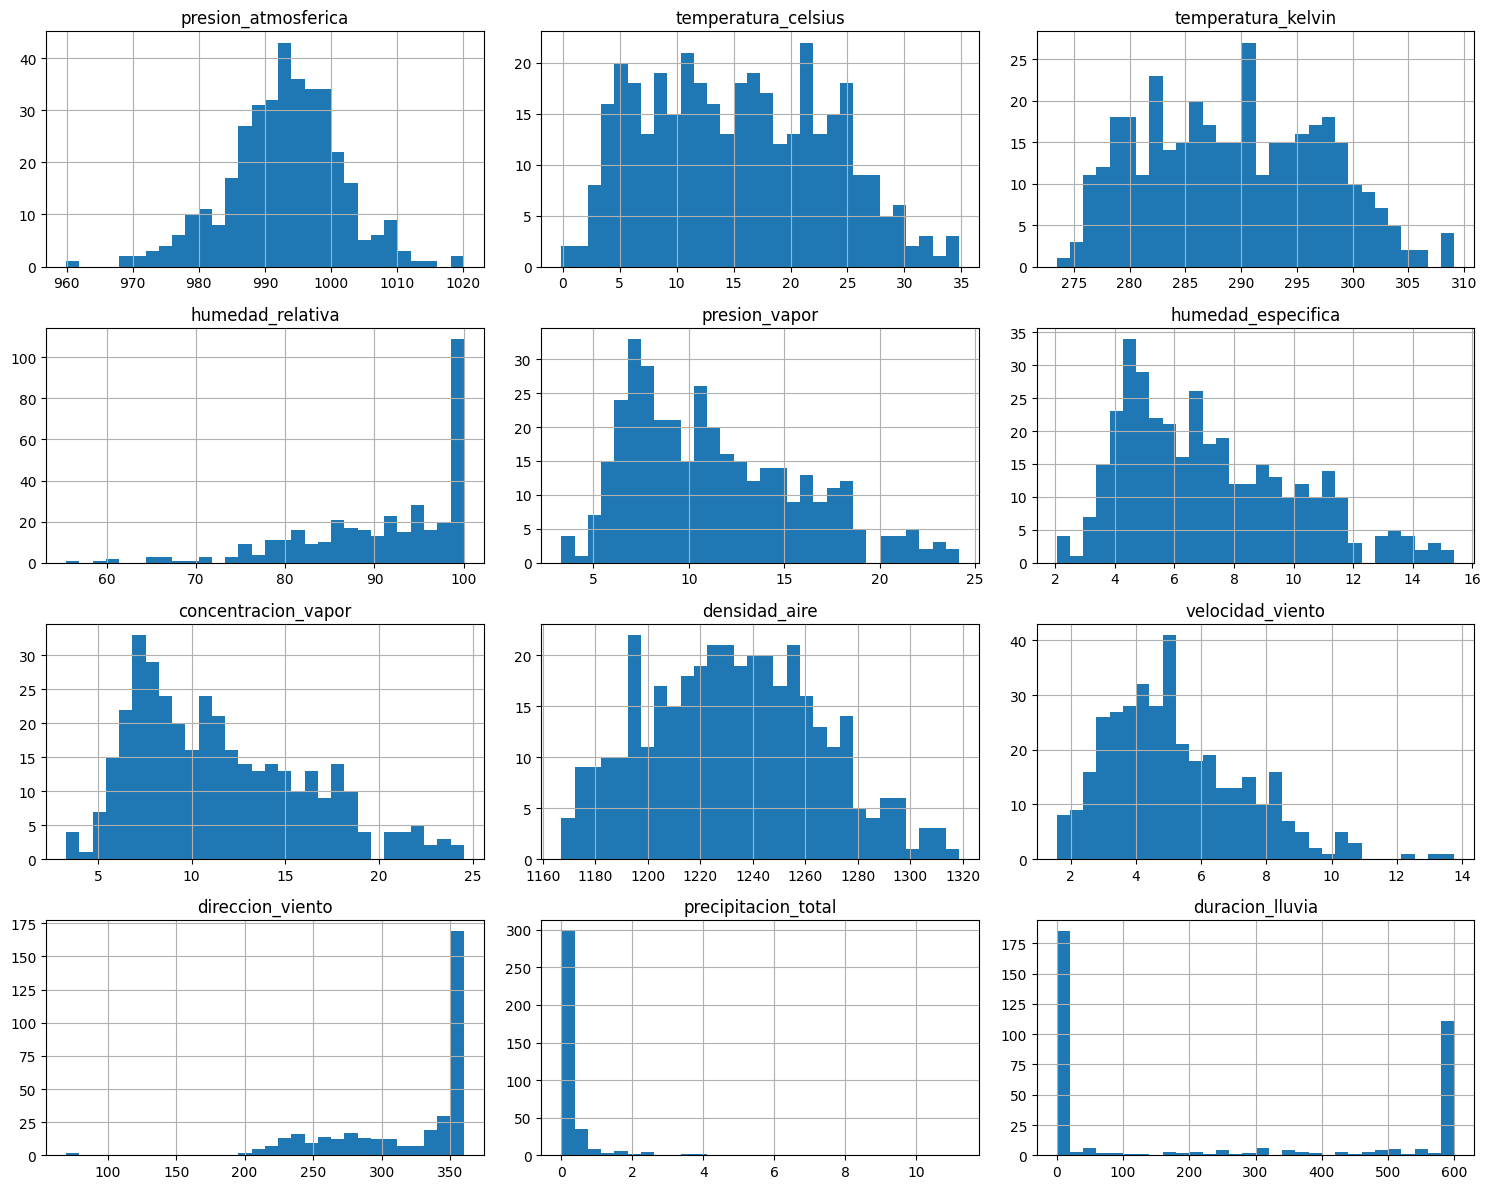

In [22]:
indicadores_diarios.hist(figsize=(15, 12), bins=30)
plt.tight_layout()
plt.show()

Se hizo un histograma para cada una de las 12 columnas. La presión tiene forma de campana, la temperatura está repartida entre 0 y 35 °C por el cambio de estaciones, y la humedad relativa se junta cerca del 100% porque son máximos diarios. En precipitacion_total y duracion_lluvia muchos días quedan en 0 porque no llovió.

8. Utiliza el dataframe de indicadores diarios para crear un nuevo dataframe `indicadores_mensuales`. Para ello:
- Crea una nueva columna `mes` a partir de la fecha que se encuentra en el índice.
- Haciendo uso de `groupby()`, calcula los promedios mensuales y conserva únicamente las columnas `humedad_relativa`, `temperatura_celsius` y `velocidad_viento` en el nuevo dataframe.

In [23]:
indicadores_diarios['mes'] = pd.to_datetime(indicadores_diarios.index).month

columnas = ['humedad_relativa', 'temperatura_celsius', 'velocidad_viento']
indicadores_mensuales = indicadores_diarios.groupby('mes')[columnas].mean()
indicadores_mensuales

,humedad_relativa,temperatura_celsius,velocidad_viento
mes,,,
1,89.776129,6.821290,5.031935
2,85.719655,8.962414,7.489655
3,85.372903,9.683871,6.421290
4,80.938667,16.879667,4.997000
5,87.464839,17.135484,4.865806
6,94.256000,22.212000,5.296667
7,85.959355,24.336129,4.830323
8,92.002581,26.097742,5.040323
9,97.570000,21.571667,4.153333


9. Construye el mismo dataframe mensual, pero esta vez utilizando la función `pivot_table()`.
- Añade la columna `indice_calor` usando la fórmula de Thom (*Temperature - Humidity Index*, TDI):
> `temperatura_celsius + 0.33 x humedad_relativa - 0.7 x velocidad_viento - 4`

In [24]:
indicadores_mensuales_pivot = indicadores_diarios.pivot_table(index='mes', values=columnas, aggfunc='mean')
indicadores_mensuales_pivot

,humedad_relativa,temperatura_celsius,velocidad_viento
mes,,,
1,89.776129,6.821290,5.031935
2,85.719655,8.962414,7.489655
3,85.372903,9.683871,6.421290
4,80.938667,16.879667,4.997000
5,87.464839,17.135484,4.865806
6,94.256000,22.212000,5.296667
7,85.959355,24.336129,4.830323
8,92.002581,26.097742,5.040323
9,97.570000,21.571667,4.153333


In [25]:
indicadores_mensuales_pivot['indice_calor'] = (indicadores_mensuales_pivot['temperatura_celsius']
                                               + 0.33 * indicadores_mensuales_pivot['humedad_relativa']
                                               - 0.7 * indicadores_mensuales_pivot['velocidad_viento']
                                               - 4)
indicadores_mensuales_pivot

,humedad_relativa,temperatura_celsius,velocidad_viento,indice_calor
mes,,,,
1,89.776129,6.821290,5.031935,28.925058
2,85.719655,8.962414,7.489655,28.007141
3,85.372903,9.683871,6.421290,29.362026
4,80.938667,16.879667,4.997000,36.091527
5,87.464839,17.135484,4.865806,38.592816
6,94.256000,22.212000,5.296667,45.608813
7,85.959355,24.336129,4.830323,45.321490
8,92.002581,26.097742,5.040323,48.930368
9,97.570000,21.571667,4.153333,46.862433


Con pivot_table() sale la misma tabla que con groupby(): los mismos meses, las mismas columnas y los mismos valores.

Después se agregó indice_calor con la fórmula de Thom. Sale más alto en verano (agosto, 48.93) y más bajo en invierno (febrero, 28.01).

10. Recuerda que de las cuatro funciones estudiadas para manipular la estructura del dataframe:
- `melt/pivot` hacen las transformaciones de manera controlada, es decir puedes
definir por medio de sus parámetros qué variables quedarán como índices, columnas y valores.
- `stack/unstack` la conversión se aplica siempre sobre los niveles inferiores de index/columns.
- Convierte el dataframe del ejercicio anterior a formato largo usando: `melt()` y `stack()` y comenta las diferencias.

In [26]:
largo_melt = indicadores_mensuales_pivot.reset_index().melt(id_vars='mes', var_name='indicador', value_name='valor')
largo_melt

,mes,indicador,valor
0,1,humedad_relativa,89.776129
1,2,humedad_relativa,85.719655
2,3,humedad_relativa,85.372903
3,4,humedad_relativa,80.938667
4,5,humedad_relativa,87.464839
5,6,humedad_relativa,94.256000
6,7,humedad_relativa,85.959355
7,8,humedad_relativa,92.002581
8,9,humedad_relativa,97.570000
9,10,humedad_relativa,96.950645


In [27]:
largo_stack = indicadores_mensuales_pivot.stack()
largo_stack

mes                     
1    humedad_relativa       89.776129
     temperatura_celsius     6.821290
     velocidad_viento        5.031935
     indice_calor           28.925058
2    humedad_relativa       85.719655
     temperatura_celsius     8.962414
     velocidad_viento        7.489655
     indice_calor           28.007141
3    humedad_relativa       85.372903
     temperatura_celsius     9.683871
     velocidad_viento        6.421290
     indice_calor           29.362026
4    humedad_relativa       80.938667
     temperatura_celsius    16.879667
     velocidad_viento        4.997000
     indice_calor           36.091527
5    humedad_relativa       87.464839
     temperatura_celsius    17.135484
     velocidad_viento        4.865806
     indice_calor           38.592816
6    humedad_relativa       94.256000
     temperatura_celsius    22.212000
     velocidad_viento        5.296667
     indice_calor           45.608813
7    humedad_relativa       85.959355
     temperatura_celsius    24.336129
     velocidad_viento        4.830323
     indice_calor           45.321490
8    humedad_relativa       92.002581
     temperatura_celsius    26.097742
     velocidad_viento        5.040323
     indice_calor           48.930368
9    humedad_relativa       97.570000
     temperatura_celsius    21.571667
     velocidad_viento        4.153333
     indice_calor           46.862433
10   humedad_relativa       96.950645
     temperatura_celsius    14.089355
     velocidad_viento        5.675484
     indice_calor           38.110229
11   humedad_relativa       96.983333
     temperatura_celsius    10.561667
     velocidad_viento        4.399000
     indice_calor           35.486867
12   humedad_relativa       97.510968
     temperatura_celsius     5.680000
     velocidad_viento        4.817097
     indice_calor           30.486652
dtype: float64

Las dos funciones pasan el dataframe a formato largo con 48 valores (12 meses × 4 indicadores), pero lo acomodan diferente:

- melt() regresa un DataFrame con las columnas mes, indicador y valor. Aquí uno decide qué columna se queda como identificador (id_vars) y cómo se llaman las columnas nuevas (var_name y value_name). Primero se usó reset_index() para que mes fuera una columna. Los datos quedan ordenados por indicador: primero los 12 meses de humedad, luego los de temperatura, etc.

- stack() regresa una Serie con un índice de dos niveles (mes e indicador). No se puede elegir qué apilar, siempre toma el nivel de las columnas y lo pasa al índice. Los datos quedan ordenados por mes: el mes 1 con sus 4 indicadores, luego el mes 2, etc.

---

**Declaración de uso de IA**

*   Anthropic. (2026). *Claude (Claude Opus 5.5)* [Modelo de lenguaje grande], utilizado para generación de código, depuración de errores y apoyo en la interpretación de resultados. https://claude.ai/
